In [ ]:
# Setup & Dependencies
!pip -q install ftfy

In [ ]:
# Imports
import os
import re
import json
import html
import random
import hashlib
import unicodedata
import warnings
from collections import Counter, defaultdict
from typing import Dict, List, Optional, Tuple, Any

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML

import ftfy

warnings.filterwarnings('ignore')
random.seed(42)
np.random.seed(42)

In [ ]:
# GCP Authentication & Config
from google.colab import auth

auth.authenticate_user()
print("GCP authentication successful!")

PROJECT_ID = "msda-llm-finetuning"
RAW_BUCKET = "msda-llm-raw-data"
PROCESSED_BUCKET = "msda-llm-processed-data"

!gcloud config set project {PROJECT_ID} --quiet

DATA_DIR = "./data"
PROCESSED_DIR = f"{DATA_DIR}/processed"
for d in [DATA_DIR, PROCESSED_DIR, f"{PROCESSED_DIR}/theory", f"{PROCESSED_DIR}/code", f"{PROCESSED_DIR}/math"]:
    os.makedirs(d, exist_ok=True)

print(f"Project: {PROJECT_ID}")

GCP authentication successful!
Updated property [core/project].
Project: msda-llm-finetuning


In [ ]:
auth.authenticate_user(clear_output=False)

# Verify authentication
!gcloud auth list

   Credentialed Accounts
ACTIVE  ACCOUNT
*       manjot1191@gmail.com

To set the active account, run:
    $ gcloud config set account `ACCOUNT`



In [ ]:
from google.cloud import storage
import os

# Create directories
DATA_DIR = "./data"
os.makedirs(f"{DATA_DIR}/raw/theory", exist_ok=True)
os.makedirs(f"{DATA_DIR}/raw/code", exist_ok=True)
os.makedirs(f"{DATA_DIR}/raw/math", exist_ok=True)

# Initialize client
client = storage.Client(project="msda-llm-finetuning")
bucket = client.bucket("msda-llm-raw-data")

# Files to download
files = [
    ("theory/ds_concepts.parquet", "./data/raw/theory/ds_concepts.parquet"),
    ("theory/github_interview.parquet", "./data/raw/theory/github_interview.parquet"),
    ("theory/treasury.parquet", "./data/raw/theory/treasury.parquet"),
    ("theory/dsqa.parquet", "./data/raw/theory/dsqa.parquet"),
    ("code/ds_coder.parquet", "./data/raw/code/ds_coder.parquet"),
    ("code/code_alpaca_filtered.parquet", "./data/raw/code/code_alpaca_filtered.parquet"),
    ("math/numina_filtered.parquet", "./data/raw/math/numina_filtered.parquet"),
    ("math/mathqa_filtered.parquet", "./data/raw/math/mathqa_filtered.parquet"),
    ("math/aqua_train_filtered.parquet", "./data/raw/math/aqua_train_filtered.parquet"),
    ("math/aqua_val_filtered.parquet", "./data/raw/math/aqua_val_filtered.parquet"),
]

print("Downloading raw datasets from GCS...\n")

for gcs_path, local_path in files:
    print(f"   Downloading {gcs_path}...")
    blob = bucket.blob(gcs_path)
    blob.download_to_filename(local_path)

print("\nRaw data downloaded!")

# Verify
!ls -lh ./data/raw/theory/
!ls -lh ./data/raw/code/
!ls -lh ./data/raw/math/



Raw data downloaded!
total 380K
-rw-r--r-- 1 root root 209K Nov 29 04:34 ds_concepts.parquet
-rw-r--r-- 1 root root    0 Nov 29 04:21 ds_concepts.parquet_.gstmp
-rw-r--r-- 1 root root  21K Nov 29 04:34 dsqa.parquet
-rw-r--r-- 1 root root    0 Nov 29 04:21 dsqa.parquet_.gstmp
-rw-r--r-- 1 root root  97K Nov 29 04:34 github_interview.parquet
-rw-r--r-- 1 root root    0 Nov 29 04:21 github_interview.parquet_.gstmp
-rw-r--r-- 1 root root  41K Nov 29 04:34 treasury.parquet
-rw-r--r-- 1 root root    0 Nov 29 04:21 treasury.parquet_.gstmp
total 20M
-rw-r--r-- 1 root root 300K Nov 29 04:34 code_alpaca_filtered.parquet
-rw-r--r-- 1 root root    0 Nov 29 04:21 code_alpaca_filtered.parquet_.gstmp
-rw-r--r-- 1 root root  19M Nov 29 04:34 ds_coder.parquet
-rw-r--r-- 1 root root    0 Nov 29 04:21 ds_coder.parquet_.gstmp
total 219M
-rw-r--r-- 1 root root 2.1M Nov 29 04:34 aqua_train_filtered.parquet
-rw-r--r-- 1 root root 7.8K Nov 29 04:34 aqua_val_filtered.parquet
-rw-r--r-- 1 root root 517K Nov 2

In [ ]:
# Load Raw Datasets
print("Loading raw datasets...\n")

raw_datasets = {"theory": {}, "code": {}, "math": {}}

# Theory
for name in ["ds_concepts", "github_interview", "treasury", "dsqa"]:
    path = f"{DATA_DIR}/raw/theory/{name}.parquet"
    if os.path.exists(path):
        raw_datasets["theory"][name] = pd.read_parquet(path)
        print(f"   Theory/{name}: {len(raw_datasets['theory'][name]):,} rows")

# Code
for name in ["ds_coder", "code_alpaca_filtered"]:
    path = f"{DATA_DIR}/raw/code/{name}.parquet"
    if os.path.exists(path):
        raw_datasets["code"][name] = pd.read_parquet(path)
        print(f"   Code/{name}: {len(raw_datasets['code'][name]):,} rows")

# Math
for name in ["numina_filtered", "mathqa_filtered", "aqua_train_filtered", "aqua_val_filtered"]:
    path = f"{DATA_DIR}/raw/math/{name}.parquet"
    if os.path.exists(path):
        raw_datasets["math"][name] = pd.read_parquet(path)
        print(f"   Math/{name}: {len(raw_datasets['math'][name]):,} rows")

print("\nAll datasets loaded!")

Loading raw datasets...

   Theory/ds_concepts: 1,070 rows
   Theory/github_interview: 324 rows
   Theory/treasury: 166 rows
   Theory/dsqa: 158 rows
   Code/ds_coder: 17,311 rows
   Code/code_alpaca_filtered: 2,228 rows
   Math/numina_filtered: 136,435 rows
   Math/mathqa_filtered: 1,736 rows
   Math/aqua_train_filtered: 7,857 rows
   Math/aqua_val_filtered: 13 rows

All datasets loaded!


In [ ]:
# Utility Functions
def show_samples(data: List[Dict], n: int = 3, title: str = ""):
    """Display sample conversations."""
    if title:
        print(f"\n{'='*70}")
        print(f"{title}")
        print('='*70)

    for i, item in enumerate(data[:n]):
        print(f"\n--- Sample {i+1} ---")
        for msg in item.get("messages", []):
            role = msg["role"].upper()
            content = msg["content"]
            # Truncate long content for display
            if len(content) > 600:
                content = content[:600] + "..."
            print(f"[{role}]:\n{content}\n")

def compute_hash(text: str) -> str:
    """Compute MD5 hash for deduplication."""
    return hashlib.md5(text.encode('utf-8', errors='ignore')).hexdigest()

def save_jsonl(data: List[Dict], filepath: str):
    """Save data to JSONL format."""
    with open(filepath, 'w', encoding='utf-8') as f:
        for item in data:
            f.write(json.dumps(item, ensure_ascii=False) + '\n')
    print(f"   Saved: {filepath} ({len(data):,} examples)")

def upload_to_gcs(local_path: str, gcs_path: str):
    """Upload file to GCS."""
    full_gcs_path = f"gs://{PROCESSED_BUCKET}/{gcs_path}"
    os.system(f"gsutil -q cp {local_path} {full_gcs_path}")
    print(f"   Uploaded: {full_gcs_path}")

def format_conversation(user_content: str, assistant_content: str, system_prompt: str = None) -> Dict:
    """Create a conversation in the standard format."""
    messages = []
    if system_prompt:
        messages.append({"role": "system", "content": system_prompt})
    messages.append({"role": "user", "content": user_content})
    messages.append({"role": "assistant", "content": assistant_content})
    return {"messages": messages}

# System prompts for each category
THEORY_SYSTEM_PROMPT = "You are a Data Science expert. Provide clear, accurate explanations of data science concepts, machine learning techniques, and statistical methods."

CODE_SYSTEM_PROMPT = "You are a Data Science coding expert. Write clean, efficient, well-documented Python code for data science tasks including data manipulation, visualization, and machine learning."

MATH_SYSTEM_PROMPT = "You are a mathematics expert specializing in statistics, probability, and quantitative reasoning for data science. Provide step-by-step solutions with clear explanations."

print("Utility functions defined!")

Utility functions defined!


In [ ]:
# Base Text Cleaning Functions
def fix_encoding(text: str) -> str:
    """Fix encoding issues using ftfy."""
    if not isinstance(text, str):
        return str(text) if text is not None else ""
    text = ftfy.fix_text(text)
    text = html.unescape(text)
    return text

def normalize_whitespace(text: str) -> str:
    """Normalize whitespace while preserving intentional structure."""
    # Replace various unicode spaces
    text = re.sub(r'[\u00a0\u2000-\u200b\u202f\u205f\u3000]', ' ', text)
    # Normalize newlines
    text = re.sub(r'\r\n', '\n', text)
    text = re.sub(r'\r', '\n', text)
    # Remove excessive newlines (more than 2)
    text = re.sub(r'\n{3,}', '\n\n', text)
    # Remove trailing whitespace per line
    text = '\n'.join(line.rstrip() for line in text.split('\n'))
    # Remove multiple spaces (but not at line start for code indentation)
    text = re.sub(r'([^\n]) {2,}', r'\1 ', text)
    return text.strip()

def remove_control_chars(text: str) -> str:
    """Remove control characters except newlines and tabs."""
    return ''.join(char for char in text if unicodedata.category(char) != 'Cc' or char in '\n\t')

def base_clean(text: str) -> str:
    """Apply base cleaning to any text."""
    if not text:
        return ""
    text = fix_encoding(text)
    text = remove_control_chars(text)
    text = normalize_whitespace(text)
    return text

print("Base cleaning functions defined!")

Base cleaning functions defined!


In [ ]:
# THEORY-Specific Preprocessing

def preprocess_theory_text(text: str) -> str:
    """Clean theory/conceptual text."""
    if not text:
        return ""

    text = base_clean(text)

    # Remove emoji markers commonly found in treasury dataset
    text = re.sub(r'[‍⭐️🚀]+', '', text)
    text = re.sub(r'\s*‍\s*', ' ', text)  # Remove zero-width joiner

    # Normalize quotes
    text = re.sub(r'["""]', '"', text)
    text = re.sub(r"[''']", "'", text)

    # Normalize dashes
    text = re.sub(r'[–—]', '-', text)

    # Clean up bullet points to be consistent
    text = re.sub(r'^[\s]*[•●○◦▪▫►▻➢➣➤]\s*', '- ', text, flags=re.MULTILINE)

    # Remove markdown artifacts but keep content
    text = re.sub(r'\*\*([^*]+)\*\*', r'\1', text)  # **bold** -> bold
    text = re.sub(r'\*([^*]+)\*', r'\1', text)      # *italic* -> italic

    # Clean multiple spaces
    text = re.sub(r' {2,}', ' ', text)

    return text.strip()

def is_valid_theory_answer(answer: str) -> bool:
    """Check if theory answer is valid (not placeholder)."""
    if not answer:
        return False
    answer_lower = answer.lower().strip()
    # Filter out placeholder answers
    invalid_patterns = [
        'answer here',
        'todo',
        'tbd',
        'n/a',
        'coming soon',
        'to be added'
    ]
    for pattern in invalid_patterns:
        if answer_lower == pattern or answer_lower.startswith(pattern):
            return False
    # Must have minimum content
    if len(answer.split()) < 3:
        return False
    return True

def is_valid_theory_question(question: str) -> bool:
    """Check if theory question is valid."""
    if not question:
        return False
    # Must have minimum length
    if len(question) < 10:
        return False
    return True

print("Theory preprocessing functions defined!")

Theory preprocessing functions defined!


In [ ]:
# CODE-Specific Preprocessing
def preprocess_code_instruction(text: str) -> str:
    """Clean instruction/prompt text for code tasks."""
    if not text:
        return ""

    text = base_clean(text)

    # Normalize quotes in natural language (not in code)
    text = re.sub(r'["""]', '"', text)
    text = re.sub(r"[''']", "'", text)

    return text.strip()

def preprocess_code_block(code: str) -> str:
    """
    Clean code while preserving structure.
    CRITICAL: Don't break indentation or syntax!
    """
    if not code:
        return ""

    # Fix encoding
    code = fix_encoding(code)

    # Remove control characters except newlines and tabs
    code = remove_control_chars(code)

    # Normalize line endings
    code = code.replace('\r\n', '\n').replace('\r', '\n')

    # Remove trailing whitespace per line (safe for Python)
    code = '\n'.join(line.rstrip() for line in code.split('\n'))

    # Remove excessive blank lines (more than 2)
    code = re.sub(r'\n{4,}', '\n\n\n', code)

    # Remove Python REPL prompts
    code = re.sub(r'^>>> ?', '', code, flags=re.MULTILINE)
    code = re.sub(r'^\.\.\. ?', '', code, flags=re.MULTILINE)

    # Remove Jupyter prompts
    code = re.sub(r'^In \[\d+\]: ?', '', code, flags=re.MULTILINE)
    code = re.sub(r'^Out\[\d+\]: ?', '', code, flags=re.MULTILINE)

    # Remove markdown code fences if present
    code = re.sub(r'^```python\s*\n?', '', code)
    code = re.sub(r'^```\s*\n?', '', code)
    code = re.sub(r'\n?```\s*$', '', code)

    return code.strip()

def is_valid_code_output(code: str, min_lines: int = 1) -> bool:
    """Check if code output is valid."""
    if not code:
        return False
    lines = [l for l in code.split('\n') if l.strip()]
    if len(lines) < min_lines:
        return False
    # Should have some code-like content
    return len(code) >= 10

print("Code preprocessing functions defined!")

Code preprocessing functions defined!


In [ ]:
# MATH-Specific Preprocessing

def preprocess_math_text(text: str) -> str:
    """
    Clean math text while preserving mathematical notation.
    """
    if not text:
        return ""

    # Fix encoding CAREFULLY
    text = ftfy.fix_text(text, fix_character_width=False)
    text = html.unescape(text)
    text = remove_control_chars(text)

    # Normalize line endings
    text = text.replace('\r\n', '\n').replace('\r', '\n')

    # Normalize quotes (outside LaTeX should be fine)
    text = re.sub(r'["""]', '"', text)
    text = re.sub(r"[''']", "'", text)

    # Remove excessive newlines
    text = re.sub(r'\n{3,}', '\n\n', text)

    # Clean up spaces (but careful around LaTeX)
    text = re.sub(r' {2,}', ' ', text)

    return text.strip()

def format_mathqa_options(options_str: str) -> str:
    """Format MathQA options string into clean format."""
    # Input format: "a ) 7 , b ) 11 , c ) 14 , d ) 17 , e ) 20"
    if not options_str:
        return ""

    # Clean up spacing
    options_str = re.sub(r'\s+', ' ', options_str.strip())

    # Split by comma and format each option
    parts = options_str.split(',')
    formatted = []
    for part in parts:
        part = part.strip()
        # Normalize "a )" to "A)" - FIX: removed the lambda, use simpler approach
        part = re.sub(r'^([a-eA-E])\s*\)', lambda m: m.group(1).upper() + ')', part)
        # Fix double letters like "A)A)1" -> "A) 1"
        part = re.sub(r'^([A-E])\)[A-E]\)', r'\1) ', part)
        formatted.append(part)

    return '\n'.join(formatted)

def format_aqua_options(options_array) -> str:
    """Format AQuA options (numpy array) into clean format."""
    # Input format: numpy array like ["A)value1", "B)value2", ...]
    if options_array is None:
        return ""

    if isinstance(options_array, np.ndarray):
        options_list = options_array.tolist()
    elif isinstance(options_array, list):
        options_list = options_array
    else:
        return str(options_array)

    return '\n'.join(str(opt) for opt in options_list)

def is_valid_math(text: str, min_chars: int = 15) -> bool:
    """Check if math content is valid."""
    if not text or len(text) < min_chars:
        return False
    return True

print("Math preprocessing functions defined!")

Math preprocessing functions defined!


In [ ]:
# Process THEORY Datasets
print("PROCESSING THEORY DATASETS")

processed_theory = []
theory_stats = {}

# 1. DS Concepts (1,070 rows)
# Columns: Question, Answer
if "ds_concepts" in raw_datasets["theory"]:
    print("\n--- Processing: DS Concepts ---")
    df = raw_datasets["theory"]["ds_concepts"]

    count_before = len(df)
    valid_count = 0

    for _, row in df.iterrows():
        question = preprocess_theory_text(str(row['Question']))
        answer = preprocess_theory_text(str(row['Answer']))

        if is_valid_theory_question(question) and is_valid_theory_answer(answer):
            conv = format_conversation(question, answer, THEORY_SYSTEM_PROMPT)
            processed_theory.append(conv)
            valid_count += 1

    theory_stats["ds_concepts"] = {"before": count_before, "after": valid_count}
    print(f"   Before: {count_before:,} | After: {valid_count:,} | Removed: {count_before - valid_count}")
    show_samples(processed_theory[-3:], 2, "DS Concepts - Processed Samples")

# 2. GitHub Interview (324 rows)
# Columns: Category, Questions, Answers
if "github_interview" in raw_datasets["theory"]:
    print("\n--- Processing: GitHub Interview ---")
    df = raw_datasets["theory"]["github_interview"]

    count_before = len(df)
    valid_count = 0

    for _, row in df.iterrows():
        category = str(row.get('Category', '')).strip()
        question = preprocess_theory_text(str(row['Questions']))
        answer = preprocess_theory_text(str(row['Answers']))

        # Optionally include category context
        if category and category.lower() not in question.lower():
            question = f"[{category}] {question}"

        if is_valid_theory_question(question) and is_valid_theory_answer(answer):
            conv = format_conversation(question, answer, THEORY_SYSTEM_PROMPT)
            processed_theory.append(conv)
            valid_count += 1

    theory_stats["github_interview"] = {"before": count_before, "after": valid_count}
    print(f"   Before: {count_before:,} | After: {valid_count:,} | Removed: {count_before - valid_count}")
    show_samples(processed_theory[-3:], 2, "GitHub Interview - Processed Samples")

# 3. Treasury (166 rows) - Has 19 "Answer here" placeholders!
# Columns: question, answer
if "treasury" in raw_datasets["theory"]:
    print("\n--- Processing: Treasury ---")
    df = raw_datasets["theory"]["treasury"]

    count_before = len(df)
    valid_count = 0
    placeholder_count = 0

    for _, row in df.iterrows():
        question = preprocess_theory_text(str(row['question']))
        answer = preprocess_theory_text(str(row['answer']))

        if not is_valid_theory_answer(answer):
            placeholder_count += 1
            continue

        if is_valid_theory_question(question):
            conv = format_conversation(question, answer, THEORY_SYSTEM_PROMPT)
            processed_theory.append(conv)
            valid_count += 1

    theory_stats["treasury"] = {"before": count_before, "after": valid_count}
    print(f"   Before: {count_before:,} | After: {valid_count:,} | Placeholders removed: {placeholder_count}")
    show_samples(processed_theory[-3:], 2, "Treasury - Processed Samples")

# 4. DSQA (158 rows)
# Columns: Question, Answer
if "dsqa" in raw_datasets["theory"]:
    print("\n--- Processing: DSQA ---")
    df = raw_datasets["theory"]["dsqa"]

    count_before = len(df)
    valid_count = 0

    for _, row in df.iterrows():
        question = preprocess_theory_text(str(row['Question']))
        answer = preprocess_theory_text(str(row['Answer']))

        if is_valid_theory_question(question) and is_valid_theory_answer(answer):
            conv = format_conversation(question, answer, THEORY_SYSTEM_PROMPT)
            processed_theory.append(conv)
            valid_count += 1

    theory_stats["dsqa"] = {"before": count_before, "after": valid_count}
    print(f"   Before: {count_before:,} | After: {valid_count:,} | Removed: {count_before - valid_count}")
    show_samples(processed_theory[-3:], 2, "DSQA - Processed Samples")

# Deduplication
print("\n--- Deduplicating Theory ---")
seen_hashes = set()
deduped_theory = []
for item in processed_theory:
    # Hash based on user message to detect duplicate questions
    user_msg = item["messages"][1]["content"]  # Index 1 because index 0 is system
    content_hash = compute_hash(user_msg.lower())
    if content_hash not in seen_hashes:
        seen_hashes.add(content_hash)
        deduped_theory.append(item)

print(f"   Before dedup: {len(processed_theory):,} | After: {len(deduped_theory):,} | Duplicates: {len(processed_theory) - len(deduped_theory)}")
processed_theory = deduped_theory

print(f"\nTotal Theory examples: {len(processed_theory):,}")

PROCESSING THEORY DATASETS

--- Processing: DS Concepts ---
   Before: 1,070 | After: 1,070 | Removed: 0

DS Concepts - Processed Samples

--- Sample 1 ---
[SYSTEM]:
You are a Data Science expert. Provide clear, accurate explanations of data science concepts, machine learning techniques, and statistical methods.

[USER]:
What are the key stages in a data mining project?

[ASSISTANT]:
A data mining project starts with understanding the business problem, followed by understanding and preparing the data, developing and evaluating models, and concludes with deploying the model into production.


--- Sample 2 ---
[SYSTEM]:
You are a Data Science expert. Provide clear, accurate explanations of data science concepts, machine learning techniques, and statistical methods.

[USER]:
What is information extraction?

[ASSISTANT]:
Information extraction systematically identifies specific information within unstructured data and converts it into a structured format, which can then be used in various 

In [ ]:
# Process CODE Datasets
print("PROCESSING CODE DATASETS")

processed_code = []
code_stats = {}

# 1. DS Coder (17,311 rows)
# Use: instruction, output (ignore 'text' and 'input' fields)
if "ds_coder" in raw_datasets["code"]:
    print("\n--- Processing: DS Coder ---")
    df = raw_datasets["code"]["ds_coder"]

    count_before = len(df)
    valid_count = 0

    for _, row in df.iterrows():
        instruction = preprocess_code_instruction(str(row.get('instruction', '')))
        output = preprocess_code_block(str(row.get('output', '')))

        # Skip if instruction or output is too short
        if len(instruction) < 10:
            continue
        if not is_valid_code_output(output):
            continue

        conv = format_conversation(instruction, output, CODE_SYSTEM_PROMPT)
        processed_code.append(conv)
        valid_count += 1

    code_stats["ds_coder"] = {"before": count_before, "after": valid_count}
    print(f"   Before: {count_before:,} | After: {valid_count:,} | Removed: {count_before - valid_count}")
    show_samples(processed_code[-3:], 2, "DS Coder - Processed Samples")

# 2. CodeAlpaca Filtered (2,228 rows)
# Columns: instruction, input, output
if "code_alpaca_filtered" in raw_datasets["code"]:
    print("\n--- Processing: CodeAlpaca ---")
    df = raw_datasets["code"]["code_alpaca_filtered"]

    count_before = len(df)
    valid_count = 0

    for _, row in df.iterrows():
        instruction = preprocess_code_instruction(str(row.get('instruction', '')))
        input_text = str(row.get('input', '')).strip()
        output = preprocess_code_block(str(row.get('output', '')))

        # Combine instruction and input if input exists
        if input_text and input_text.lower() not in ['', 'nan', 'none', 'not applicable', 'no input']:
            input_text = preprocess_code_instruction(input_text)
            user_content = f"{instruction}\n\nInput:\n{input_text}"
        else:
            user_content = instruction

        if len(user_content) < 10:
            continue
        if not is_valid_code_output(output):
            continue

        conv = format_conversation(user_content, output, CODE_SYSTEM_PROMPT)
        processed_code.append(conv)
        valid_count += 1

    code_stats["code_alpaca"] = {"before": count_before, "after": valid_count}
    print(f"   Before: {count_before:,} | After: {valid_count:,} | Removed: {count_before - valid_count}")
    show_samples(processed_code[-3:], 2, "CodeAlpaca - Processed Samples")

# Deduplication
print("\n--- Deduplicating Code ---")
seen_hashes = set()
deduped_code = []
for item in processed_code:
    user_msg = item["messages"][1]["content"]
    content_hash = compute_hash(user_msg.lower())
    if content_hash not in seen_hashes:
        seen_hashes.add(content_hash)
        deduped_code.append(item)

print(f"   Before dedup: {len(processed_code):,} | After: {len(deduped_code):,} | Duplicates: {len(processed_code) - len(deduped_code)}")
processed_code = deduped_code

print(f"\nTotal Code examples: {len(processed_code):,}")

PROCESSING CODE DATASETS

--- Processing: DS Coder ---
   Before: 17,311 | After: 17,311 | Removed: 0

DS Coder - Processed Samples

--- Sample 1 ---
[SYSTEM]:
You are a Data Science coding expert. Write clean, efficient, well-documented Python code for data science tasks including data manipulation, visualization, and machine learning.

[USER]:
Create a machine learning model to predict a binary class.

[ASSISTANT]:
# import the necessary libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# preprocess the data
df = pd.read_csv('data.csv')
X = df.drop('target', axis=1)
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# train the model
lr = LogisticRegression().fit(X_train, y_train)

# evaluate the model
train_score = lr.score(X_train, y_train)
test_score = lr.score(X_test, y_test)
print(f"Train score: {train_score}")
print(f"

In [ ]:
# Process MATH Datasets

print("PROCESSING MATH DATASETS")

processed_math = []
math_stats = {}

# 1. NuminaMath Filtered (~136K rows)
# Columns: source, problem, solution, messages
if "numina_filtered" in raw_datasets["math"]:
    print("\n--- Processing: NuminaMath ---")
    df = raw_datasets["math"]["numina_filtered"]

    count_before = len(df)
    valid_count = 0

    for _, row in df.iterrows():
        problem = preprocess_math_text(str(row.get('problem', '')))
        solution = preprocess_math_text(str(row.get('solution', '')))

        if not is_valid_math(problem) or not is_valid_math(solution):
            continue

        conv = format_conversation(problem, solution, MATH_SYSTEM_PROMPT)
        processed_math.append(conv)
        valid_count += 1

    math_stats["numina"] = {"before": count_before, "after": valid_count}
    print(f"   Before: {count_before:,} | After: {valid_count:,} | Removed: {count_before - valid_count}")
    show_samples(processed_math[-5:], 3, "NuminaMath - Processed Samples")

# 2. MathQA Filtered (1,736 rows)
# Columns: Problem, Rationale, options, correct, annotated_formula, linear_formula, category
if "mathqa_filtered" in raw_datasets["math"]:
    print("\n--- Processing: MathQA ---")
    df = raw_datasets["math"]["mathqa_filtered"]

    count_before = len(df)
    valid_count = 0

    for _, row in df.iterrows():
        problem = preprocess_math_text(str(row.get('Problem', '')))
        rationale = preprocess_math_text(str(row.get('Rationale', '')))
        options = format_mathqa_options(str(row.get('options', '')))
        correct = str(row.get('correct', '')).strip().upper()

        # Build question with options
        if options:
            question = f"{problem}\n\nOptions:\n{options}"
        else:
            question = problem

        # Build answer with correct choice
        if correct:
            answer = f"{rationale}\n\nCorrect Answer: {correct}"
        else:
            answer = rationale

        if not is_valid_math(question) or len(answer) < 10:
            continue

        conv = format_conversation(question, answer, MATH_SYSTEM_PROMPT)
        processed_math.append(conv)
        valid_count += 1

    math_stats["mathqa"] = {"before": count_before, "after": valid_count}
    print(f"   Before: {count_before:,} | After: {valid_count:,} | Removed: {count_before - valid_count}")
    show_samples(processed_math[-5:], 2, "MathQA - Processed Samples")

# 3. AQuA-RAT Train (7,857 rows)
# Columns: question, options (numpy array!), rationale, correct
if "aqua_train_filtered" in raw_datasets["math"]:
    print("\n--- Processing: AQuA Train ---")
    df = raw_datasets["math"]["aqua_train_filtered"]

    count_before = len(df)
    valid_count = 0

    for _, row in df.iterrows():
        question = preprocess_math_text(str(row.get('question', '')))
        rationale = preprocess_math_text(str(row.get('rationale', '')))
        options = format_aqua_options(row.get('options'))
        correct = str(row.get('correct', '')).strip().upper()

        # Build question with options
        if options:
            full_question = f"{question}\n\nOptions:\n{options}"
        else:
            full_question = question

        # Build answer
        if correct:
            answer = f"{rationale}\n\nCorrect Answer: {correct}"
        else:
            answer = rationale

        if not is_valid_math(full_question) or len(answer) < 10:
            continue

        conv = format_conversation(full_question, answer, MATH_SYSTEM_PROMPT)
        processed_math.append(conv)
        valid_count += 1

    math_stats["aqua_train"] = {"before": count_before, "after": valid_count}
    print(f"   Before: {count_before:,} | After: {valid_count:,} | Removed: {count_before - valid_count}")
    show_samples(processed_math[-5:], 2, "AQuA Train - Processed Samples")

# 4. AQuA-RAT Validation (13 rows)
if "aqua_val_filtered" in raw_datasets["math"]:
    print("\n--- Processing: AQuA Validation ---")
    df = raw_datasets["math"]["aqua_val_filtered"]

    count_before = len(df)
    valid_count = 0

    for _, row in df.iterrows():
        question = preprocess_math_text(str(row.get('question', '')))
        rationale = preprocess_math_text(str(row.get('rationale', '')))
        options = format_aqua_options(row.get('options'))
        correct = str(row.get('correct', '')).strip().upper()

        if options:
            full_question = f"{question}\n\nOptions:\n{options}"
        else:
            full_question = question

        if correct:
            answer = f"{rationale}\n\nCorrect Answer: {correct}"
        else:
            answer = rationale

        if not is_valid_math(full_question) or len(answer) < 10:
            continue

        conv = format_conversation(full_question, answer, MATH_SYSTEM_PROMPT)
        processed_math.append(conv)
        valid_count += 1

    math_stats["aqua_val"] = {"before": count_before, "after": valid_count}
    print(f"   Before: {count_before:,} | After: {valid_count:,}")

# Deduplication
print("\n--- Deduplicating Math ---")
seen_hashes = set()
deduped_math = []
for item in processed_math:
    user_msg = item["messages"][1]["content"]
    # For math, hash first 200 chars to catch near-duplicates
    content_hash = compute_hash(user_msg[:200].lower())
    if content_hash not in seen_hashes:
        seen_hashes.add(content_hash)
        deduped_math.append(item)

print(f"   Before dedup: {len(processed_math):,} | After: {len(deduped_math):,} | Duplicates: {len(processed_math) - len(deduped_math)}")
processed_math = deduped_math

print(f"\nTotal Math examples: {len(processed_math):,}")

PROCESSING MATH DATASETS

--- Processing: NuminaMath ---
   Before: 136,435 | After: 136,433 | Removed: 2

NuminaMath - Processed Samples

--- Sample 1 ---
[SYSTEM]:
You are a mathematics expert specializing in statistics, probability, and quantitative reasoning for data science. Provide step-by-step solutions with clear explanations.

[USER]:
A certain shopping mall purchased a batch of daily necessities at a unit price of $20$ yuan. If they are sold at a unit price of $30$ yuan, then 400 items can be sold in half a month. According to sales experience, increasing the selling price will lead to a decrease in sales volume. Specifically, for every $1$ yuan increase in selling price, the sales volume decreases by $20$ items. What is the unit price at which the sales volume is maximized in half a month?

[ASSISTANT]:
To solve this problem, we first establish the relationship between the selling price, sales volume, and profit. Let's denote the selling price by $x$ yuan and the sales profi

In [ ]:
# Save & Upload to GCS
print("SAVING & UPLOADING TO GCS")

# Save Theory
print("\nTheory:")
theory_path = f"{PROCESSED_DIR}/theory/theory_train.jsonl"
save_jsonl(processed_theory, theory_path)
upload_to_gcs(theory_path, "theory/theory_train.jsonl")

# Save Code
print("\nCode:")
code_path = f"{PROCESSED_DIR}/code/code_train.jsonl"
save_jsonl(processed_code, code_path)
upload_to_gcs(code_path, "code/code_train.jsonl")

# Save Math
print("\nMath:")
math_path = f"{PROCESSED_DIR}/math/math_train.jsonl"
save_jsonl(processed_math, math_path)
upload_to_gcs(math_path, "math/math_train.jsonl")

print("\nAll processed data saved and uploaded!")

SAVING & UPLOADING TO GCS

Theory:
   Saved: ./data/processed/theory/theory_train.jsonl (1,657 examples)
   Uploaded: gs://msda-llm-processed-data/theory/theory_train.jsonl

Code:
   Saved: ./data/processed/code/code_train.jsonl (19,443 examples)
   Uploaded: gs://msda-llm-processed-data/code/code_train.jsonl

Math:
   Saved: ./data/processed/math/math_train.jsonl (138,115 examples)
   Uploaded: gs://msda-llm-processed-data/math/math_train.jsonl

All processed data saved and uploaded!


In [ ]:
# Verify GCS Upload
print("\nVerifying GCS uploads:")
!gsutil ls -lh gs://{PROCESSED_BUCKET}/


Verifying GCS uploads:
                                 gs://msda-llm-processed-data/code/
                                 gs://msda-llm-processed-data/math/
                                 gs://msda-llm-processed-data/theory/


In [ ]:
# Processing Summary
print("PREPROCESSING SUMMARY")

print("\nTHEORY DATASETS:")
for name, stats in theory_stats.items():
    retention = 100 * stats["after"] / stats["before"] if stats["before"] > 0 else 0
    print(f"   {name:25s}: {stats['before']:>6,} → {stats['after']:>6,} ({retention:.1f}%)")
print(f"   {'FINAL (after dedup)':25s}: {len(processed_theory):>6,}")

print("\nCODE DATASETS:")
for name, stats in code_stats.items():
    retention = 100 * stats["after"] / stats["before"] if stats["before"] > 0 else 0
    print(f"   {name:25s}: {stats['before']:>6,} → {stats['after']:>6,} ({retention:.1f}%)")
print(f"   {'FINAL (after dedup)':25s}: {len(processed_code):>6,}")

print("\nMATH DATASETS:")
for name, stats in math_stats.items():
    retention = 100 * stats["after"] / stats["before"] if stats["before"] > 0 else 0
    print(f"   {name:25s}: {stats['before']:>6,} → {stats['after']:>6,} ({retention:.1f}%)")
print(f"   {'FINAL (after dedup)':25s}: {len(processed_math):>6,}")

grand_total = len(processed_theory) + len(processed_code) + len(processed_math)
print(f"GRAND TOTAL: {grand_total:,}")
print(f"   Theory: {len(processed_theory):,} ({100*len(processed_theory)/grand_total:.1f}%)")
print(f"   Code:   {len(processed_code):,} ({100*len(processed_code)/grand_total:.1f}%)")
print(f"   Math:   {len(processed_math):,} ({100*len(processed_math)/grand_total:.1f}%)")

PREPROCESSING SUMMARY

THEORY DATASETS:
   ds_concepts              :  1,070 →  1,070 (100.0%)
   github_interview         :    324 →    324 (100.0%)
   treasury                 :    166 →    147 (88.6%)
   dsqa                     :    158 →    158 (100.0%)
   FINAL (after dedup)      :  1,657

CODE DATASETS:
   ds_coder                 : 17,311 → 17,311 (100.0%)
   code_alpaca              :  2,228 →  2,224 (99.8%)
   FINAL (after dedup)      : 19,443

MATH DATASETS:
   numina                   : 136,435 → 136,433 (100.0%)
   mathqa                   :  1,736 →  1,736 (100.0%)
   aqua_train               :  7,857 →  7,857 (100.0%)
   aqua_val                 :     13 →     13 (100.0%)
   FINAL (after dedup)      : 138,115
GRAND TOTAL: 159,215
   Theory: 1,657 (1.0%)
   Code:   19,443 (12.2%)
   Math:   138,115 (86.7%)


In [ ]:
# EDA on Processed Data
print("EDA ON PROCESSED DATA")

def analyze_processed(data: List[Dict], name: str):
    """Analyze processed data."""
    user_lengths = []
    assistant_lengths = []

    for item in data:
        for msg in item["messages"]:
            if msg["role"] == "user":
                user_lengths.append(len(msg["content"]))
            elif msg["role"] == "assistant":
                assistant_lengths.append(len(msg["content"]))

    print(f"\n{name}")
    print(f"   Examples: {len(data):,}")
    print(f"   User msg - Avg: {np.mean(user_lengths):.0f}, Median: {np.median(user_lengths):.0f}, Max: {max(user_lengths):,}")
    print(f"   Asst msg - Avg: {np.mean(assistant_lengths):.0f}, Median: {np.median(assistant_lengths):.0f}, Max: {max(assistant_lengths):,}")

    return user_lengths, assistant_lengths

theory_user, theory_asst = analyze_processed(processed_theory, "Theory")
code_user, code_asst = analyze_processed(processed_code, "Code")
math_user, math_asst = analyze_processed(processed_math, "Math")

EDA ON PROCESSED DATA

Theory
   Examples: 1,657
   User msg - Avg: 58, Median: 53, Max: 409
   Asst msg - Avg: 333, Median: 249, Max: 2,668

Code
   Examples: 19,443
   User msg - Avg: 473, Median: 215, Max: 7,428
   Asst msg - Avg: 1335, Median: 1017, Max: 9,924

Math
   Examples: 138,115
   User msg - Avg: 283, Median: 232, Max: 5,465
   Asst msg - Avg: 1337, Median: 1188, Max: 10,075


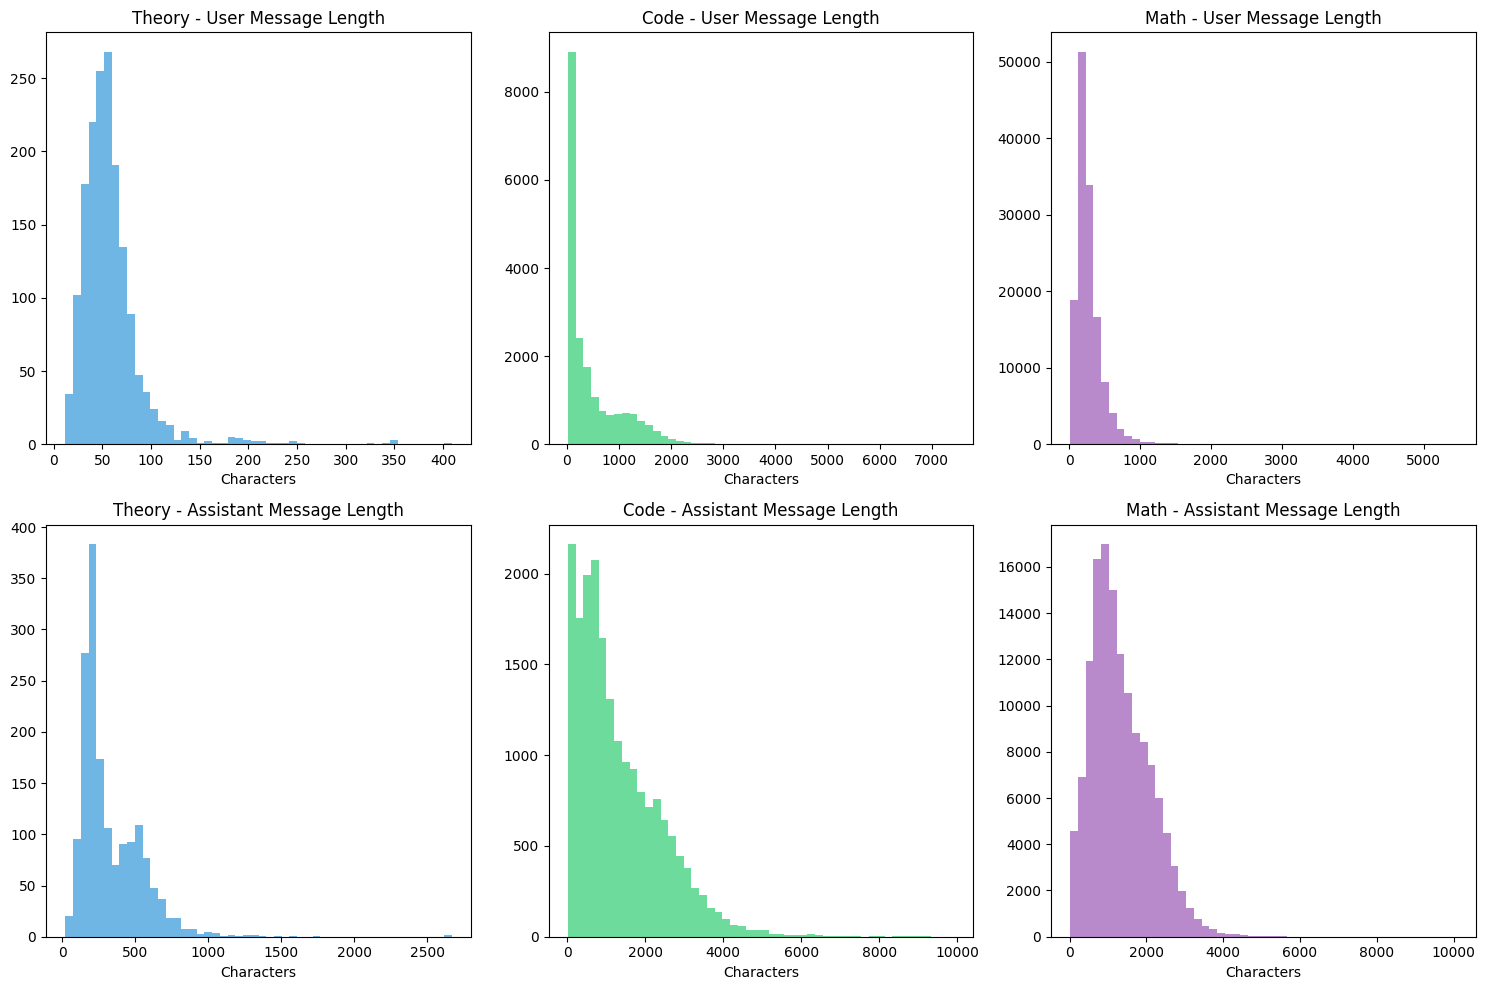

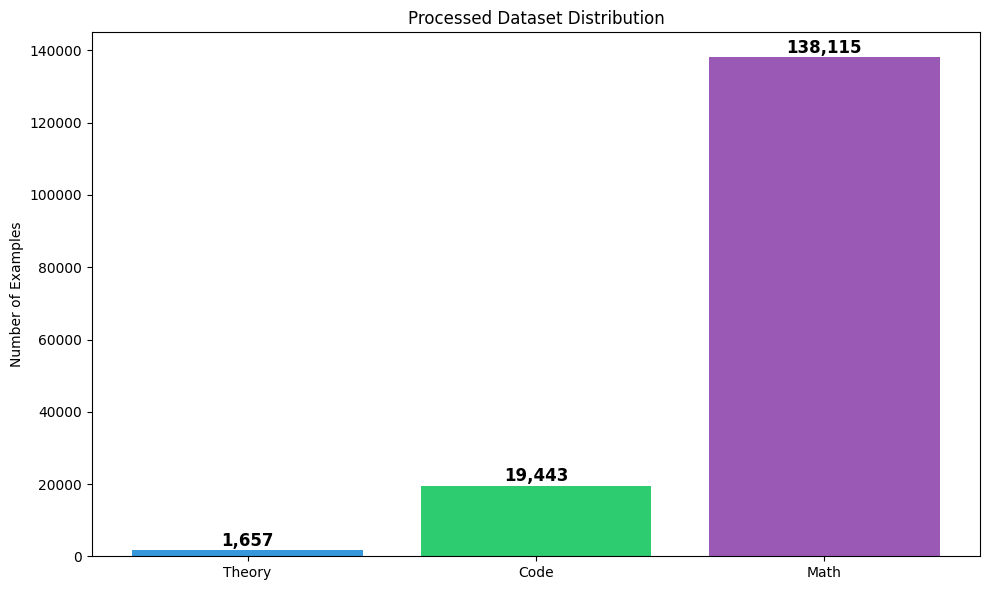


Preprocessing complete!


In [ ]:
# Visualizations
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# User message lengths
axes[0, 0].hist(theory_user, bins=50, alpha=0.7, color='#3498db')
axes[0, 0].set_title('Theory - User Message Length')
axes[0, 0].set_xlabel('Characters')

axes[0, 1].hist(code_user, bins=50, alpha=0.7, color='#2ecc71')
axes[0, 1].set_title('Code - User Message Length')
axes[0, 1].set_xlabel('Characters')

axes[0, 2].hist(math_user, bins=50, alpha=0.7, color='#9b59b6')
axes[0, 2].set_title('Math - User Message Length')
axes[0, 2].set_xlabel('Characters')

# Assistant message lengths
axes[1, 0].hist(theory_asst, bins=50, alpha=0.7, color='#3498db')
axes[1, 0].set_title('Theory - Assistant Message Length')
axes[1, 0].set_xlabel('Characters')

axes[1, 1].hist(code_asst, bins=50, alpha=0.7, color='#2ecc71')
axes[1, 1].set_title('Code - Assistant Message Length')
axes[1, 1].set_xlabel('Characters')

axes[1, 2].hist(math_asst, bins=50, alpha=0.7, color='#9b59b6')
axes[1, 2].set_title('Math - Assistant Message Length')
axes[1, 2].set_xlabel('Characters')

plt.tight_layout()
plt.savefig(f"{PROCESSED_DIR}/message_length_distributions.png", dpi=150)
plt.show()

# Final distribution
fig, ax = plt.subplots(figsize=(10, 6))
categories = ['Theory', 'Code', 'Math']
counts = [len(processed_theory), len(processed_code), len(processed_math)]
colors = ['#3498db', '#2ecc71', '#9b59b6']

bars = ax.bar(categories, counts, color=colors)
ax.set_ylabel('Number of Examples')
ax.set_title('Processed Dataset Distribution')

for bar, count in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
            f'{count:,}', ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig(f"{PROCESSED_DIR}/dataset_distribution.png", dpi=150)
plt.show()

print("\nPreprocessing complete!")

In [ ]:
# Validate JSONL Format
print("JSONL FORMAT VALIDATION")

def validate_jsonl(filepath: str, name: str) -> bool:
    """Validate JSONL file format."""
    print(f"\n📋 Validating: {name}")

    errors = []
    valid_count = 0

    with open(filepath, 'r', encoding='utf-8') as f:
        for i, line in enumerate(f):
            try:
                data = json.loads(line)

                if "messages" not in data:
                    errors.append(f"Line {i+1}: Missing 'messages'")
                    continue

                messages = data["messages"]
                has_user = any(m.get("role") == "user" for m in messages)
                has_assistant = any(m.get("role") == "assistant" for m in messages)

                if not has_user:
                    errors.append(f"Line {i+1}: Missing user message")
                if not has_assistant:
                    errors.append(f"Line {i+1}: Missing assistant message")

                valid_count += 1

            except json.JSONDecodeError as e:
                errors.append(f"Line {i+1}: JSON error - {e}")

    print(f"   Valid: {valid_count:,} | Errors: {len(errors)}")

    if errors[:3]:
        print("   First errors:", errors[:3])

    return len(errors) == 0

validate_jsonl(f"{PROCESSED_DIR}/theory/theory_train.jsonl", "Theory")
validate_jsonl(f"{PROCESSED_DIR}/code/code_train.jsonl", "Code")
validate_jsonl(f"{PROCESSED_DIR}/math/math_train.jsonl", "Math")

JSONL FORMAT VALIDATION

📋 Validating: Theory
   Valid: 1,657 | Errors: 0

📋 Validating: Code
   Valid: 19,443 | Errors: 0

📋 Validating: Math
   Valid: 138,115 | Errors: 0


True